# Lab 3-08（選讀）：PDF 解析——切塊之前，文字就已經壞了

**目標**：用 pymupdf 做一份含雙欄、表格、圖片的小 PDF，看純文字抽取怎麼把它弄壞，再用版面資訊修回來；最後看真正的解析器（MinerU、olmocr）輸出長什麼樣。

**你會學到**
- PDF 裡沒有「段落」「表格」，只有「某個座標畫了某個字」
- 雙欄會交錯、表格會攤平、上標會變成普通數字
- 多模態 RAG 的第一步：把文字、表格、圖片區塊分開
- MinerU 這類解析器輸出什麼、什麼時候才值得用

**前置**：Lab 3-02。不需要 GPU，不下載模型。原理見 `00_concepts.md` 第 8、9 節。

**對應投影片**：「PDF 表格：轉成 Markdown」「選型：RAG 框架」

![PDF 抽字：閱讀順序](images/pdf_reading_order.jpg)

*圖：左邊是純文字抽取的讀法，朱紅箭頭一行一行橫掃，左右兩欄和表格各列被串成一長條；右邊先做版面分析，認出左欄、右欄、表格三個區塊，再依人類的順序讀。*

## Step 1：做一份海風科技的季報 PDF

為了知道「正確答案」長什麼樣，我們自己產生 PDF：標題、雙欄內文、一張表格、一行公式、一張長條圖。
很多排版軟體輸出 PDF 時是**一橫行一橫行**寫的（先寫左欄第 1 行、再寫右欄第 1 行），這裡照做。檔案放暫存資料夾，不進 repo。

In [1]:
import io
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pymupdf

from course_utils.viz import setup_cjk

setup_cjk()
FONT = "china-t"  # pymupdf 內建的繁中字型

left = ["本季整體可用性維持在目標以上，", "但九月的壓測暴露通知管線的瓶頸。", "gull-notify 消費者只開了 8 個，",
        "而 topic 有 24 個分區，", "通知平均延遲 38 分鐘。", "雙 11 前已將消費者固定為 24 個。"]
right = ["金流方面，tide-pay v3.4.2 上線後", "未再發生重複扣款。", "收單行 acq-a 有兩次短暫中斷，",
         "皆在 5 分鐘內切換到 acq-b，", "對使用者影響有限。", "第四季重點是凍結期的變更管理。"]
table = [["服務", "可用性", "SEV1", "SEV2"], ["breakwater", "99.98%", "0", "1"],
         ["lighthouse-auth", "99.91%", "1", "0"], ["tide-pay", "99.95%", "0", "2"], ["current-mq", "99.99%", "0", "1"]]


def make_report(path: Path) -> None:
    doc = pymupdf.open()
    page = doc.new_page(width=595, height=842)
    page.insert_text((50, 60), "海風科技 2026 年第三季維運季報", fontname=FONT, fontsize=16)
    for i, (l, r) in enumerate(zip(left, right)):  # 一橫行一橫行寫入
        page.insert_text((50, 100 + 16 * i), l, fontname=FONT, fontsize=10)
        page.insert_text((310, 100 + 16 * i), r, fontname=FONT, fontsize=10)
    widths = [180, 90, 60, 60]
    for i, row in enumerate(table):  # 畫格線、填文字
        x = 50
        for w, cell in zip(widths, row):
            page.draw_rect(pymupdf.Rect(x, 230 + 22 * i, x + w, 252 + 22 * i), color=(0, 0, 0), width=0.6)
            page.insert_text((x + 5, 245 + 22 * i), cell, fontname=FONT, fontsize=10)
            x += w
    page.insert_text((50, 380), "可用性 = 1 - 停機分鐘 / 總分鐘", fontname=FONT, fontsize=11)
    fig, ax = plt.subplots(figsize=(4, 2.2))
    ax.bar(["7月", "8月", "9月"], [3, 1, 5], color="#4f81bd")
    ax.set_title("每月事故數")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=100)
    plt.close(fig)
    page.insert_image(pymupdf.Rect(50, 400, 350, 565), stream=buf.getvalue())
    page.insert_text((50, 580), "圖 1：每月事故數", fontname=FONT, fontsize=9)
    doc.save(path)


pdf_path = Path(tempfile.mkdtemp()) / "haifeng_q3_report.pdf"
make_report(pdf_path)
print(pdf_path, pdf_path.stat().st_size, "bytes")

/tmp/tmpe0hbwje8/haifeng_q3_report.pdf 287594 bytes


## Step 2：人眼看到的樣子

把頁面渲染成圖片。這是人讀到的版面：左右兩欄、一張表、一張圖。

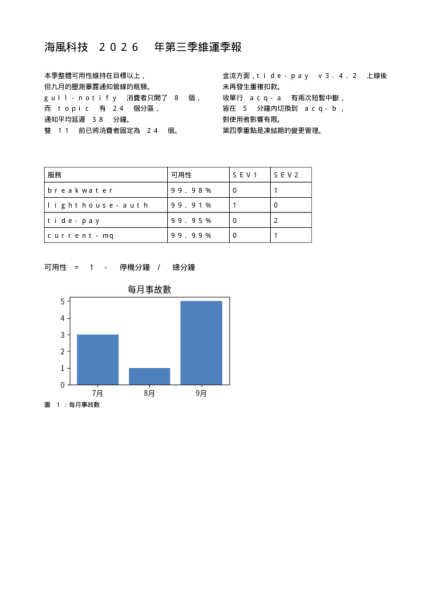

In [2]:
page = pymupdf.open(pdf_path)[0]
pix = page.get_pixmap(dpi=80)
img = plt.imread(io.BytesIO(pix.tobytes("png")))
plt.figure(figsize=(6, 7.5))
plt.imshow(img)
plt.axis("off")
plt.show()

## Step 3：純文字抽取——雙欄交錯

`page.get_text()` 依「寫入順序」吐出文字。因為是一橫行一橫行寫的，左欄和右欄的句子被交錯接在一起。

In [3]:
raw = page.get_text()
print(raw[:330])

海風科技 2026 年第三季維運季報
本季整體可用性維持在目標以上，
金流方面，tide-pay v3.4.2 上線後
但九月的壓測暴露通知管線的瓶頸。
未再發生重複扣款。
gull-notify 消費者只開了 8 個，
收單行 acq-a 有兩次短暫中斷，
而 topic 有 24 個分區，
皆在 5 分鐘內切換到 acq-b，
通知平均延遲 38 分鐘。
對使用者影響有限。
雙 11 前已將消費者固定為 24 個。
第四季重點是凍結期的變更管理。
服務
可用性
SEV1
SEV2
breakwater
99.98%
0
1
lighthouse-auth
99.91%
1
0
tide-pay
99.95%
0
2
current-mq
99.99


「但九月的壓測暴露通知管線的瓶頸。」後面接的是「未再發生重複扣款。」——切塊後，這兩句會落在同一塊，意思全亂。
`sort=True` 會照座標由上而下、由左而右排，但兩欄在同一個高度，一樣交錯：

In [4]:
print(page.get_text(sort=True)[:300])

海風科技 2026 年第三季維運季報


本季整體可用性維持在目標以上，           金流方面，tide-pay v3.4.2 上線後
但九月的壓測暴露通知管線的瓶頸。          未再發生重複扣款。
gull-notify 消費者只開了 8 個，   收單行 acq-a 有兩次短暫中斷，
而 topic 有 24 個分區，         皆在 5 分鐘內切換到 acq-b，
通知平均延遲 38 分鐘。             對使用者影響有限。
雙 11 前已將消費者固定為 24 個。      第四季重點是凍結期的變更管理。




服務                可用


## Step 4：用版面資訊修——先切欄再讀

知道頁面是雙欄，就用 `clip` 只讀左半邊、再讀右半邊。真正的解析器會自動偵測欄位；這裡我們知道答案，直接給座標。

In [5]:
left_rect = pymupdf.Rect(0, 80, page.rect.width / 2, 200)
right_rect = pymupdf.Rect(page.rect.width / 2, 80, page.rect.width, 200)
fixed = page.get_text(clip=left_rect) + page.get_text(clip=right_rect)
print(fixed)

本季整體可用性維持在目標以上，
但九月的壓測暴露通知管線的瓶頸。
gull-notify 消費者只開了 8 個，
而 topic 有 24 個分區，
通知平均延遲 38 分鐘。
雙 11 前已將消費者固定為 24 個。
金流方面，tide-pay v3.4.2 上線後
未再發生重複扣款。
收單行 acq-a 有兩次短暫中斷，
皆在 5 分鐘內切換到 acq-b，
對使用者影響有限。
第四季重點是凍結期的變更管理。



## Step 5：表格被攤平

純文字抽取把表格變成一格一行。四個欄位的關係只剩「順序」，切塊時只要切在中間，就沒人知道 `1` 是哪個服務的哪一欄。

In [6]:
start = raw.index("服務")
print(raw[start:start + 160])

服務
可用性
SEV1
SEV2
breakwater
99.98%
0
1
lighthouse-auth
99.91%
1
0
tide-pay
99.95%
0
2
current-mq
99.99%
0
1
可用性 = 1 - 停機分鐘 / 總分鐘
圖 1：每月事故數



pymupdf 有 `find_tables()`：根據格線找出表格，`to_markdown()` 轉成 Markdown 表格。LLM 讀 Markdown 表格很在行。

In [7]:
tables = page.find_tables()
print("找到", len(tables.tables), "張表")
table_md = tables.tables[0].to_markdown()
print(table_md)

找到 1 張表
|服務|可用性|SEV1|SEV2|
|---|---|---|---|
|breakwater|99.98%|0|1|
|lighthouse-auth|99.91%|1|0|
|tide-pay|99.95%|0|2|
|current-mq|99.99%|0|1|




## Step 6：問 LLM 同一個問題，給兩種文字

In [8]:
from rag_utils import ask

question = "lighthouse-auth 第三季的可用性是多少？發生幾次 SEV1？"
for name, context in [("攤平的文字", raw[start:start + 160]), ("Markdown 表格", table_md)]:
    ans = ask([{"role": "user", "content": f"根據資料回答，簡短。\n\n資料：\n{context}\n\n問題：{question}"}])
    print(f"【{name}】{ans.strip()}")

【攤平的文字】lighthouse-auth 第三季的可用性是 99.91%，发生 1 次 SEV1。
【Markdown 表格】lighthouse-auth 第三季的可用性是 99.91%。
發生 1 次 SEV1。


這張表很小，小模型有時靠順序也猜得對；表一大、欄位一多、有合併儲存格，攤平的版本就會開始張冠李戴。
真實世界的例子在 Step 9。

## Step 7：多模態 RAG 的第一步——把非文字區塊找出來

`get_text("dict")` 回傳每個區塊的型別與座標：`type 0` 是文字、`type 1` 是圖片。再加上 `find_tables` 的表格範圍，就能把頁面拆成三類區塊。
拆開之後才能分別處理：文字切塊、表格轉 Markdown、圖片交給視覺模型寫描述。

In [9]:
blocks = []
table_boxes = [pymupdf.Rect(t.bbox) for t in tables.tables]
for b in page.get_text("dict")["blocks"]:
    rect = pymupdf.Rect(b["bbox"])
    if b["type"] == 1:
        blocks.append(("圖片", rect))
    elif any(tb.contains(rect) for tb in table_boxes):
        continue  # 表格裡的文字，交給表格處理
    else:
        blocks.append(("文字", rect))
blocks += [("表格", tb) for tb in table_boxes]
for kind, rect in blocks:
    print(f"{kind}  {[round(v) for v in rect]}")

文字  [50, 44, 338, 63]
文字  [50, 90, 550, 102]
文字  [50, 106, 400, 118]
文字  [50, 122, 490, 134]
文字  [50, 138, 490, 150]
文字  [50, 154, 400, 166]
文字  [50, 170, 460, 182]
文字  [50, 369, 270, 382]
圖片  [50, 400, 350, 565]
文字  [50, 571, 131, 582]
表格  [50, 230, 440, 340]


把區塊畫回頁面上：

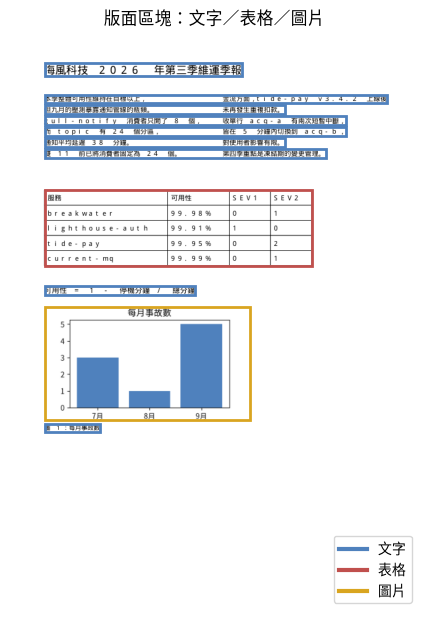

In [10]:
import matplotlib.patches as patches

colors = {"文字": "#4f81bd", "表格": "#c0504d", "圖片": "#d9a520"}
scale = 80 / 72  # 渲染 dpi ÷ PDF 單位
fig, ax = plt.subplots(figsize=(6, 7.5))
ax.imshow(img)
for kind, r in blocks:
    ax.add_patch(patches.Rectangle((r.x0 * scale, r.y0 * scale), r.width * scale, r.height * scale,
                                   fill=False, edgecolor=colors[kind], linewidth=2))
for kind, c in colors.items():
    ax.plot([], [], color=c, lw=3, label=kind)
ax.legend(loc="lower right")
ax.axis("off")
ax.set_title("版面區塊：文字／表格／圖片")
plt.show()

圖片可以直接取出位元組，之後交給視覺語言模型（VLM）寫一段描述，再把描述當文字建索引。本課的 `qwen2.5:3b` 看不懂圖，這一步只示範取圖。

In [11]:
xref = page.get_images()[0][0]
image_info = pymupdf.open(pdf_path).extract_image(xref)
print("圖片格式：", image_info["ext"], "，大小：", len(image_info["image"]), "bytes，", image_info["width"], "×", image_info["height"])

圖片格式： png ，大小： 6733 bytes， 400 × 220


## Step 8：公式與上標

我們自己寫的公式是純文字，所以抽得出來。真實論文的公式是一堆定位過的符號，上標、下標、分數線各自獨立，抽出來就散了。下一步看真實例子。

In [12]:
print(page.get_text(clip=pymupdf.Rect(40, 365, 400, 390)))

可用性 = 1 - 停機分鐘 / 總分鐘



## Step 9：真實論文——同一張表，兩種解析器

`data/parser_sample/` 放了 *Attention Is All You Need* 第 8 頁 Table 2 的兩種解析結果（論文首頁聲明允許學術用途重製表格）：
- `transformer_table2_pymupdf.txt`：pymupdf `get_text()` 的輸出
- `transformer_table2_olmocr.md`：2025 年課程用 olmocr（以視覺語言模型讀頁面圖片的解析器）處理的輸出

In [13]:
import json

sample = Path("data/parser_sample")
pm_text = (sample / "transformer_table2_pymupdf.txt").read_text()
olm_text = (sample / "transformer_table2_olmocr.md").read_text()
print(pm_text[200:520])

LEU
Training Cost (FLOPs)
EN-DE
EN-FR
EN-DE
EN-FR
ByteNet [18]
23.75
Deep-Att + PosUnk [39]
39.2
1.0 · 1020
GNMT + RL [38]
24.6
39.92
2.3 · 1019
1.4 · 1020
ConvS2S [9]
25.16
40.46
9.6 · 1018
1.5 · 1020
MoE [32]
26.03
40.56
2.0 · 1019
1.2 · 1020
Deep-Att + PosUnk Ensemble [39]
40.4
8.0 · 1020
GNMT + RL Ensemble [38]
26.


注意 `1.0 · 1020`：原文是 1.0 × 10²⁰，上標被當成普通數字接在後面，LLM 會讀成「一千零二十」。空白儲存格也消失了，`39.2` 到底是 EN-DE 還是 EN-FR 已經無從判斷。

olmocr 的版本保留了表格結構與 LaTeX：

In [14]:
print(olm_text[:900])

Table 2: The Transformer achieves better BLEU scores than previous state-of-the-art models on the English-to-German and English-to-French newstest2014 tests at a fraction of the training cost.

<table>
  <tr>
    <th rowspan="2">Model</th>
    <th colspan="2">BLEU</th>
    <th colspan="2">Training Cost (FLOPs)</th>
  </tr>
  <tr>
    <th>EN-DE</th>
    <th>EN-FR</th>
    <th>EN-DE</th>
    <th>EN-FR</th>
  </tr>
  <tr>
    <td>ByteNet [18]</td>
    <td>23.75</td>
    <td></td>
    <td></td>
    <td></td>
  </tr>
  <tr>
    <td>Deep-Att + PosUnk [39]</td>
    <td></td>
    <td>39.2</td>
    <td></td>
    <td>1.0 \cdot 10^{20}</td>
  </tr>
  <tr>
    <td>GNMT + RL [38]</td>
    <td>24.6</td>
    <td>39.92</td>
    <td>2.3 \cdot 10^{19}</td>
    <td>1.4 \cdot 10^{20}</td>
  </tr>
  <tr>
    <td>ConvS2S [9]</td>
    <td>25.16</td>
    <td>40.46</td>
    <td>9.6 \cdot 10^{18}</td>
    <td>1.5


In [15]:
meta = json.loads((sample / "metadata.json").read_text())
print("解析器：", meta["parser"], meta["parser_version"])
print("這一頁的屬性：", meta["page_attributes"])

解析器： olmocr 0.4.6
這一頁的屬性： {'pdf_page_numbers': [22764, 27124, 8], 'primary_language': 'en', 'is_rotation_valid': True, 'rotation_correction': 0, 'is_table': False, 'is_diagram': False}


有趣的是，olmocr 自己標的 `is_table` 是 `false`——表格轉對了，頁面層級的標記卻是錯的。解析器的 metadata 也要抽查，不能全信。

## Step 10：MinerU 在做什麼

MinerU 是目前常用的開源 PDF 解析器（OpenDataLab）。它不是「更聰明的 get_text」，而是一條模型管線：

```
PDF 頁面 ──▶ 版面分析模型 ──▶ 區塊：標題／段落／表格／公式／圖片／頁首頁尾
                                 │       │       │      │
                                 │       │       │      └─▶ 圖片另存成檔
                                 │       │       └─▶ 公式辨識 → LaTeX
                                 │       └─▶ 表格辨識 → HTML
                                 └─▶ 依閱讀順序排好的文字（必要時 OCR）
                                             │
                                             ▼
                       <檔名>.md  ＋  <檔名>_content_list.json  ＋  images/
```

用法是一行命令（2025 課程的 `demo.py` 就是這樣呼叫）：`mineru -p 季報.pdf -o output -m auto`。
本課**不安裝、不執行**：它要下載數 GB 的模型，最好有 GPU，處理一頁要幾秒到十幾秒。

對 RAG 最有用的是 `content_list.json`：一個區塊一筆，帶型別與頁碼。下面是**依 MinerU 文件欄位手寫的示意**（不是實際輸出），內容對應我們的季報：

In [16]:
content_list = [
    {"type": "text", "text": "海風科技 2026 年第三季維運季報", "text_level": 1, "page_idx": 0},
    {"type": "text", "text": "本季整體可用性維持在目標以上，但九月的壓測暴露通知管線的瓶頸。…", "page_idx": 0},
    {"type": "text", "text": "金流方面，tide-pay v3.4.2 上線後未再發生重複扣款。…", "page_idx": 0},
    {"type": "table", "img_path": "images/table_0.jpg", "table_caption": [],
     "table_body": "<table><tr><td>服務</td><td>可用性</td>…</tr></table>", "page_idx": 0},
    {"type": "equation", "text": "$$\\text{可用性} = 1 - \\frac{\\text{停機分鐘}}{\\text{總分鐘}}$$", "text_format": "latex", "page_idx": 0},
    {"type": "image", "img_path": "images/fig_0.jpg", "image_caption": ["圖 1：每月事故數"], "page_idx": 0},
]
print({item["type"] for item in content_list})

{'equation', 'text', 'image', 'table'}


拿到這種結構之後，每一類各走各的路，最後都變成可以建索引的文字：

In [17]:
def to_index_text(item: dict) -> str:
    if item["type"] == "text":
        return item["text"]
    if item["type"] == "table":
        return "[表格] " + item["table_body"]  # 或轉成 Markdown 表格
    if item["type"] == "equation":
        return "[公式] " + item["text"]
    if item["type"] == "image":
        return "[圖片] " + "；".join(item["image_caption"]) + "（實務上再請 VLM 寫一段描述）"
    return ""


for item in content_list:
    print(f"{item['type']:<9}→ {to_index_text(item)[:60]}")

text     → 海風科技 2026 年第三季維運季報
text     → 本季整體可用性維持在目標以上，但九月的壓測暴露通知管線的瓶頸。…
text     → 金流方面，tide-pay v3.4.2 上線後未再發生重複扣款。…
table    → [表格] <table><tr><td>服務</td><td>可用性</td>…</tr></table>
equation → [公式] $$\text{可用性} = 1 - \frac{\text{停機分鐘}}{\text{總分鐘}}$$
image    → [圖片] 圖 1：每月事故數（實務上再請 VLM 寫一段描述）


## Step 11：怎麼選

| 文件長相 | 建議 | 理由 |
|---|---|---|
| 純文字、單欄（合約、規章、技術文件匯出） | pymupdf `get_text()` | 快、零依賴，夠用 |
| 雙欄、少量格線表格 | pymupdf ＋ `clip`／`find_tables()` | 本 notebook 的做法，仍然很輕 |
| 大量表格、公式、掃描檔、複雜版面（論文、財報） | MinerU 或 Docling | 有版面與表格模型，輸出結構化區塊 |
| 圖表本身就是資訊 | 解析器取圖 ＋ VLM 寫描述 | 文字抽取拿不到圖裡的數字 |

不論選哪個，**解析放離線批次**：文件進來時解析一次、存成 Markdown／content list，再切塊建索引。不要放在使用者提問的路徑上——
解析一份文件動輒數十秒，而且同一份文件不需要每次重解析。

## 試試看

1. 把 Step 1 的表格格線拿掉（不畫 `draw_rect`），`find_tables()` 還找得到嗎？試試 `find_tables(strategy="text")`。
2. 把右欄改成從 y=160 開始（兩欄高度錯開），`get_text(sort=True)` 的結果會變好還是變壞？
3. 對 Step 9 的兩個版本各問一次「Transformer (big) 在 EN-DE 的 BLEU 是多少？訓練成本是多少 FLOPs？」，比較 LLM 的回答。

## 小結

- PDF 只記錄「哪個座標畫了哪個字」；雙欄交錯、表格攤平、上標變數字，都發生在切塊之前。
- 多模態 RAG 的第一步是把頁面拆成文字、表格、公式、圖片區塊，各自轉成可索引的文字；pymupdf 能做簡單版，MinerU／Docling 做完整版。
- 解析是離線工作：純文字 PDF 用 pymupdf，有表格公式掃描檔才上重型解析器。多模態 RAG 與 RAG-Anything 的取捨寫在 `00_concepts.md` 第 9 節；模組 3 到此結束，模組 4 把文件變成知識圖譜。